In [1]:
from google.colab import files
uploaded = files.upload()

Saving student+performance.zip to student+performance (2).zip


In [2]:
import zipfile, glob

for z in glob.glob('*.zip'):
    zipfile.ZipFile(z).extractall('.')

for z in glob.glob('*.zip'):
    zipfile.ZipFile(z).extractall('.')

print(glob.glob('*.csv'))

['student-mat.csv', 'student-por.csv']


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('student-mat.csv', sep=';')
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [5]:
print("Rows, columns:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Students with final grade G3 = 0:", (df['G3'] == 0).sum())
print(df[['studytime', 'failures', 'absences', 'G1', 'G2', 'G3']].describe())

Rows, columns: (395, 33)
Missing values: 0
Duplicate rows: 0
Students with final grade G3 = 0: 38
        studytime    failures    absences          G1          G2          G3
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000
mean     2.035443    0.334177    5.708861   10.908861   10.713924   10.415190
std      0.839240    0.743651    8.003096    3.319195    3.761505    4.581443
min      1.000000    0.000000    0.000000    3.000000    0.000000    0.000000
25%      1.000000    0.000000    0.000000    8.000000    9.000000    8.000000
50%      2.000000    0.000000    4.000000   11.000000   11.000000   11.000000
75%      2.000000    0.000000    8.000000   13.000000   13.000000   14.000000
max      4.000000    3.000000   75.000000   19.000000   19.000000   20.000000


## Cleaning decisions
- Used the Math file (student-mat.csv) only.
- Checked for missing values and duplicates and found none, so no rows were removed.
- Kept all columns, since all are valid and I only need a few of them.
- Some students have a final grade G3 = 0. I kept them, because they are real students, but I will mention this in the memo as a limit of the data.

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64
Correlation between studytime and G3: 0.098


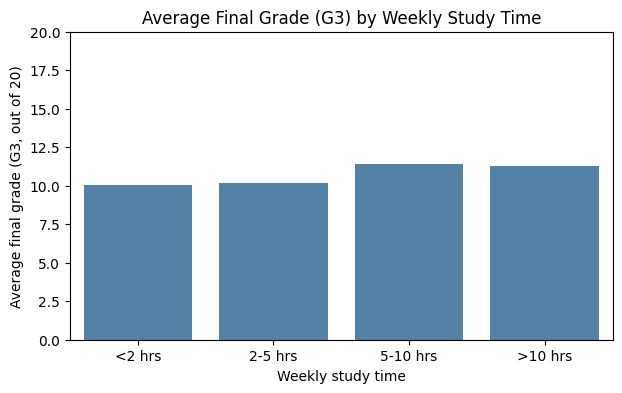

In [6]:
avg = df.groupby('studytime')['G3'].mean()
print(avg)
print("Correlation between studytime and G3:", round(df['studytime'].corr(df['G3']), 3))

labels = ['<2 hrs', '2-5 hrs', '5-10 hrs', '>10 hrs']
plt.figure(figsize=(7, 4))
sns.barplot(x=labels, y=avg.values, color='steelblue')
plt.title('Average Final Grade (G3) by Weekly Study Time')
plt.xlabel('Weekly study time')
plt.ylabel('Average final grade (G3, out of 20)')
plt.ylim(0, 20)
plt.show()

### Interpretation: Chart 1
Students who study more tend to score slightly higher, from about 10 out of 20 in the lowest study-time group to about 11 in the 5-10 hour group. The increase stops after that, and the >10 hour group is not higher than the 5-10 hour group. The correlation between study time and G3 is only 0.098, which is very weak (0 means no relationship and 1 means a perfect one). So study time alone explains very little of the difference in final grades.

studytime    0.098
failures    -0.360
G2           0.905
Name: G3, dtype: float64


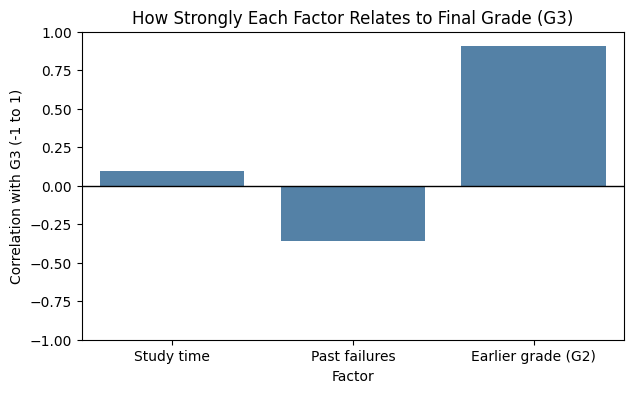

In [7]:
factors = ['studytime', 'failures', 'G2']
corrs = df[factors + ['G3']].corr()['G3'][factors]
print(corrs.round(3))

names = ['Study time', 'Past failures', 'Earlier grade (G2)']
plt.figure(figsize=(7, 4))
sns.barplot(x=names, y=corrs.values, color='steelblue')
plt.axhline(0, color='black', linewidth=1)
plt.title('How Strongly Each Factor Relates to Final Grade (G3)')
plt.xlabel('Factor')
plt.ylabel('Correlation with G3 (-1 to 1)')
plt.ylim(-1, 1)
plt.show()

### Interpretation: Chart 2
The earlier period grade (G2) has by far the strongest relationship with the final grade, at 0.905, which is very strong. Past failures have a moderate negative relationship of -0.360, meaning students with more past failures tend to score lower. Study time is the weakest of the three at 0.098. G2 is so strongly related to G3 partly because it measures the same kind of performance only a few months earlier, so it shows that grades are consistent over time, not that G2 causes G3.